In [1]:
import matplotlib.pyplot as plt

from detector import Detector
from source import Source
import numpy as np


detector_1 = Detector(2, 40, 0.1, 0.5)
detector_1.place_photomultipliers()

Z = [0, 0.5, 1, 1.5]
Q_damp = np.zeros([1000, len(Z)])
Q = np.zeros([1000, len(Z)])

for n in range(1000):
    for k, z in enumerate([0, 0.5, 1, 1.5]): # расставляем источники по вертикальной оси
        source_1 = Source(10**4, [0, 0, z])
        photons = source_1.generate_photons(1, 100)
        for photon in photons:
            cross_photons = detector_1.find_cross_point_damp(source_1.position, photon) # считаем точки пересечения, находим долетевшие фотоны
            detectors = detector_1.find_photomultiplier(cross_photons) # определяем детекторы
            hits = np.sum(detectors != -1) # считаем попадания
            photo_electrons = detector_1.generate_photo_electrons(hits) # генерируем фэ

            Q_damp[n, k] += photo_electrons # считаем собранный заряд

            cross_photons = detector_1.find_cross_point(source_1.position, photon) # считаем точки пересечения без затухания
            detectors = detector_1.find_photomultiplier(cross_photons) # определяем детекторы
            hits = np.sum(detectors != -1) # считаем попадания
            photo_electrons = detector_1.generate_photo_electrons(hits) # генерируем фэ
            Q[n, k] += photo_electrons




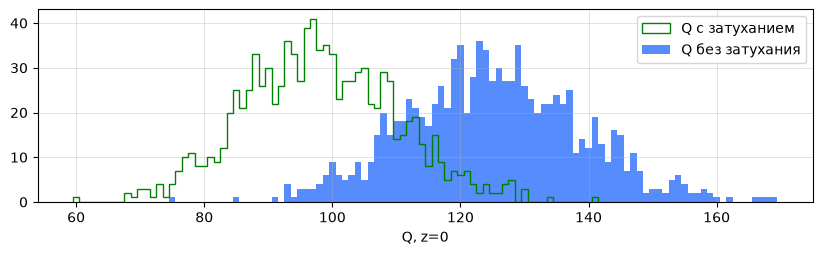

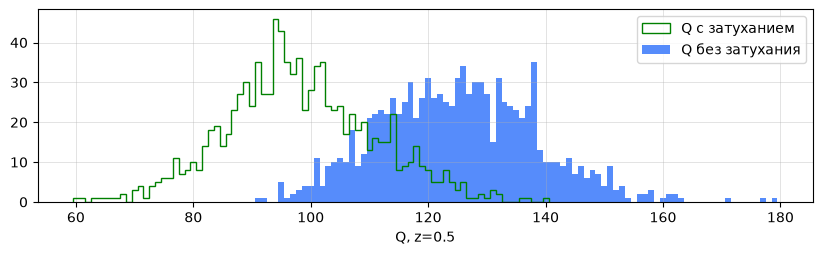

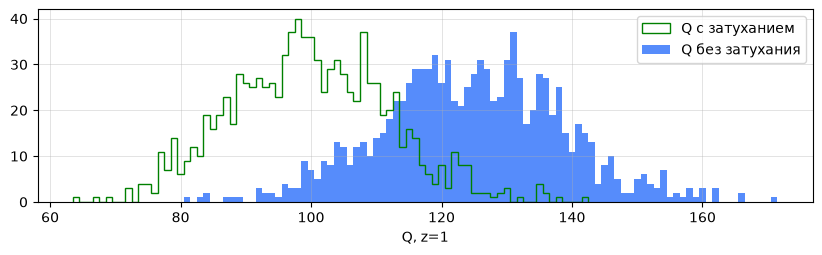

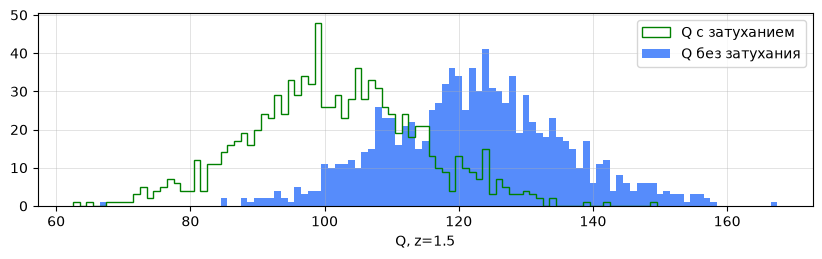

In [14]:
for k,z in enumerate(Z):
    plt.figure(figsize=(10, 2.5))
    plt.subplot(111)
    bns_d = np.arange(min(Q_damp[:, k]), max(Q_damp[:, k]) + 2) - 0.5
    bns = np.arange(min(Q[:, k]), max(Q[:, k]) + 2) - 0.5
    plt.hist(Q_damp[:, k], bins=bns_d, label='Q с затуханием', histtype='step', color='green')
    plt.hist(Q[:, k], bins=bns, label='Q без затухания')
    plt.xlabel(f'Q, z={z}')
    plt.grid()
    plt.legend()


plt.show()
